# Records and missing values

Compute mean readings by instrument while retaining the difference between zero and an absent reading.

Define the unit of observation before grouping. Each row is one reading from one instrument. The correct denominator is the number of observed values for that instrument. A measurement of zero belongs in that denominator. The result is ordered by identifier so it can be compared independently of map iteration order.

A map lookup returns the value by copy. Write the updated struct back to the map after changing the sum and count.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.go`

```go
package main

import (
	"fmt"
)

type reading struct {
	id      string
	value   int
	present bool
}

func main() {
	rows := []reading{{"A", 3, true}, {"B", 8, true}, {"A", 5, true}, {"C", 2, true}, {"B", 0, false}}
	type group struct{ sum, count int }
	groups := map[string]group{}
	for _, r := range rows {
		if !r.present {
			continue
		}
		g := groups[r.id]
		g.sum += r.value
		g.count++
		groups[r.id] = g
	}
	for _, id := range []string{"A", "B", "C"} {
		g := groups[id]
		fmt.Print(float64(g.sum)/float64(g.count), " ")
	}
}
```

## Execute the native listing

A map lookup returns the value by copy. Write the updated struct back to the map after changing the sum and count. Trace the result and error at the point where each function returns. Slice length, map lookup status and channel synchronisation are explicit parts of the interface.

In [2]:
x = [[3, 5], [8], [2]]
expected = np.asarray([sum(v) / len(v) for v in x], dtype=float)
engine, stdout = run_native(here / "native.go")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: Go
Native stdout: 4 8 2
Largest absolute difference: 0


## Read the output

Instrument B has one observed value and one missing value. Its average stays at eight. An empty instrument would need an explicit missing-output convention. The marks show the independent Python reference at each position.

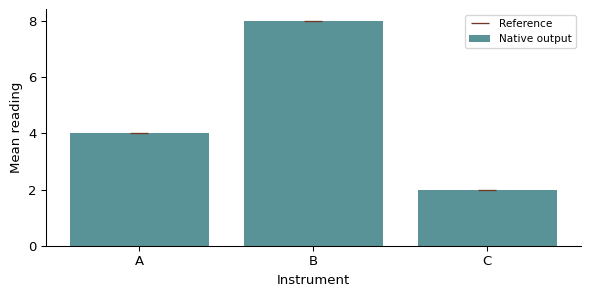

In [3]:
labels = ["A", "B", "C"]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Instrument", ylabel="Mean reading")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

Instrument B has one observed value and one missing value. Its average stays at eight. An empty instrument would need an explicit missing-output convention.

## Exercise

Add a genuine zero to B and a new instrument with no observed values. Decide on a representation for the empty result.

## References

[The Go Programming Language Specification](https://go.dev/ref/spec)